PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [72]:
import requests
import json
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
#ignore warnings
import warnings
warnings.filterwarnings("ignore")
import ScraperFC as sfc
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error


In [73]:
epl_stats = pd.read_csv("Data/stats_epl1524.csv")

In [74]:
epl_stats

,Ball possession_home,Total shots_home,Goalkeeper saves_home,Corner kicks_home,Fouls_home,Passes_home,Free kicks_home,Yellow cards_home,Shots on target_home,Hit woodwork_home,...,Touches in penalty area_away,Final third phase_away,Big saves_away,High claims_away,Errors lead to a shot_home,Punches_home,Errors lead to a shot_away,Punches_away,Errors lead to a goal_home,Errors lead to a goal_away
0,68%,14,3.0,7,0,697,7,1.0,3,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,47%,18,2.0,4,0,480,12,2.0,9,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,70%,21,2.0,6,0,592,10,3.0,6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,40%,14,3.0,8,0,384,8,2.0,7,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,47%,13,3.0,7,0,366,20,3.0,5,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,59%,14,1.0,3,13,684,11,1.0,4,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3416,60%,13,2.0,7,8,566,12,3.0,7,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3417,24%,12,3.0,3,12,227,9,4.0,6,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3418,47%,14,2.0,1,14,428,10,2.0,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [75]:
epl_stats.columns

Index(['Ball possession_home', 'Total shots_home', 'Goalkeeper saves_home',
       'Corner kicks_home', 'Fouls_home', 'Passes_home', 'Free kicks_home',
       'Yellow cards_home', 'Shots on target_home', 'Hit woodwork_home',
       'Shots off target_home', 'Blocked shots_home', 'Shots inside box_home',
       'Shots outside box_home', 'Offsides_home', 'Accurate passes_home',
       'Throw-ins_home', 'Duels_home', 'Ground duels_home',
       'Aerial duels_home', 'Total saves_home', 'Goal kicks_home',
       'Ball possession_away', 'Total shots_away', 'Goalkeeper saves_away',
       'Corner kicks_away', 'Fouls_away', 'Passes_away', 'Free kicks_away',
       'Yellow cards_away', 'Shots on target_away', 'Hit woodwork_away',
       'Shots off target_away', 'Blocked shots_away', 'Shots inside box_away',
       'Shots outside box_away', 'Offsides_away', 'Accurate passes_away',
       'Throw-ins_away', 'Duels_away', 'Ground duels_away',
       'Aerial duels_away', 'Total saves_away', 'Goal kic

In [76]:
def nan_analysis(df):
    """
    This function takes a DataFrame and returns a DataFrame with the percentage of NaN values for each column.
    Only columns with NaN values are included in the output DataFrame.
    """
    nan_percentage = df.isna().mean() * 100
    nan_percentage = nan_percentage[nan_percentage > 0].reset_index()
    nan_percentage.columns = ['Column Name', 'Percentage of NaN Values']
    nan_percentage = nan_percentage.sort_values(by='Percentage of NaN Values', ascending=False)
    return nan_percentage
nan_analysis(epl_stats)


,Column Name,Percentage of NaN Values
59,Errors lead to a goal_away,99.795322
58,Errors lead to a goal_home,99.795322
56,Errors lead to a shot_away,99.707602
54,Errors lead to a shot_home,99.707602
57,Punches_away,99.678363
55,Punches_home,99.678363
48,Big saves_home,99.590643
52,Big saves_away,99.590643
53,High claims_away,99.561404
49,High claims_home,99.561404


In [77]:
#drop the columns with more than 10% of the values as NaN  
epl_stats.dropna(thresh=len(epl_stats)*0.8, axis=1, inplace=True)
epl_stats.drop(columns=['season'], inplace=True)
nan_analysis(epl_stats)

,Column Name,Percentage of NaN Values
8,Big chances_home,18.625731
20,Big chances_away,18.625731
22,Fouled in final third_away,16.900585
10,Fouled in final third_home,16.900585
24,Long balls_away,16.081871
19,Clearances_home,16.081871
21,Tackles_away,16.081871
23,Final third entries_away,16.081871
16,Tackles won_home,16.081871
17,Total tackles_home,16.081871


In [78]:
convertible_cols,unconvertable_cols = [],[]
for col in epl_stats.columns:
    try:
        # Try converting column to numeric and then to integer
        pd.to_numeric(epl_stats[col], errors='raise').astype('Int64')
        convertible_cols.append(col)
    except:
        print(f"Column '{col}' cannot be converted to integer.")
        unconvertable_cols.append(col)
        pass  # Skip columns that can't be converted


Column 'Ball possession_home' cannot be converted to integer.
Column 'Duels_home' cannot be converted to integer.
Column 'Ground duels_home' cannot be converted to integer.
Column 'Aerial duels_home' cannot be converted to integer.
Column 'Ball possession_away' cannot be converted to integer.
Column 'Duels_away' cannot be converted to integer.
Column 'Ground duels_away' cannot be converted to integer.
Column 'Aerial duels_away' cannot be converted to integer.
Column 'Long balls_home' cannot be converted to integer.
Column 'Crosses_home' cannot be converted to integer.
Column 'Dribbles_home' cannot be converted to integer.
Column 'Tackles won_home' cannot be converted to integer.
Column 'Long balls_away' cannot be converted to integer.
Column 'Crosses_away' cannot be converted to integer.
Column 'Dribbles_away' cannot be converted to integer.
Column 'Tackles won_away' cannot be converted to integer.


In [79]:
len(unconvertable_cols)

16

In [80]:
epl_stats[unconvertable_cols]

,Ball possession_home,Duels_home,Ground duels_home,Aerial duels_home,Ball possession_away,Duels_away,Ground duels_away,Aerial duels_away,Long balls_home,Crosses_home,Dribbles_home,Tackles won_home,Long balls_away,Crosses_away,Dribbles_away,Tackles won_away
0,68%,55%,35/62 (56%),18/35 (51%),32%,45%,27/62 (44%),17/35 (49%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,47%,44%,37/85 (44%),7/15 (47%),53%,56%,48/85 (56%),8/15 (53%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,70%,53%,46/102 (45%),31/43 (72%),30%,47%,56/102 (55%),12/43 (28%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,40%,55%,62/110 (56%),16/31 (52%),60%,45%,48/110 (44%),15/31 (48%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,47%,57%,55/92 (60%),16/33 (48%),53%,43%,37/92 (40%),17/33 (52%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,59%,53%,36/64 (56%),3/9 (33%),41%,47%,28/64 (44%),6/9 (67%),32/53 (60%),1/7 (14%),14/19 (74%),64%,26/45 (58%),3/5 (60%),5/9 (56%),40%
3416,60%,52%,33/64 (52%),10/18 (56%),40%,48%,31/64 (48%),8/18 (44%),20/37 (54%),2/12 (17%),13/23 (57%),56%,25/56 (45%),3/18 (17%),9/11 (82%),71%
3417,24%,39%,28/70 (40%),11/31 (35%),76%,61%,42/70 (60%),20/31 (65%),12/38 (32%),3/9 (33%),5/8 (63%),43%,7/17 (41%),10/34 (29%),15/21 (71%),69%
3418,47%,51%,34/67 (51%),14/27 (52%),53%,49%,33/67 (49%),13/27 (48%),24/45 (53%),3/21 (14%),10/19 (53%),71%,24/54 (44%),4/21 (19%),6/12 (50%),50%


In [81]:
#check if the columns has a percentage sign, a percentage and / sign, or no sign:
flt,perc,div = [],[],[]
for i in unconvertable_cols:
    if epl_stats[i].astype(str).str.contains('%').any() and epl_stats[i].astype(str).str.contains('/').any():
        div.append(i)
    elif epl_stats[i].astype(str).str.contains('%').any() and not epl_stats[i].astype(str).str.contains('/').any():
        perc.append(i)
    else:
        flt.append(i)

In [82]:
import re

def extract_percentage_column(df, col):
    return df[col].str.extract(r'\((\d+)%\)')[0].astype(float)/100

In [83]:


for i in div:
    epl_stats[i] = extract_percentage_column(epl_stats, i)


In [84]:
def change_percentage_to_float(df, col):
    """
    Takes a DataFrame and column name. Extracts percentage values like '57%' and converts them to float (0.57).
    """
    return df[col].str.replace('%', '', regex=False).astype(float) / 100
# Apply the function to the specified columns
for col in perc:
    if epl_stats[col].astype(str).str.contains('%').any():
        print(f"Converting column '{col}' to float.")
        epl_stats[col] = change_percentage_to_float(epl_stats, col)
    else:
        print(f"Skipping column '{col}' — no '%' symbol found.")

Converting column 'Ball possession_home' to float.
Converting column 'Duels_home' to float.
Converting column 'Ball possession_away' to float.
Converting column 'Duels_away' to float.
Converting column 'Tackles won_home' to float.
Converting column 'Tackles won_away' to float.


In [85]:
epl_stats[perc].head(10)

,Ball possession_home,Duels_home,Ball possession_away,Duels_away,Tackles won_home,Tackles won_away
0,0.68,0.55,0.32,0.45,NaN,NaN
1,0.47,0.44,0.53,0.56,NaN,NaN
2,0.70,0.53,0.30,0.47,NaN,NaN
3,0.40,0.55,0.60,0.45,NaN,NaN
4,0.47,0.57,0.53,0.43,NaN,NaN
5,0.33,0.44,0.67,0.56,NaN,NaN
6,0.68,0.49,0.32,0.51,NaN,NaN
7,0.57,0.48,0.43,0.52,NaN,NaN
8,0.45,0.55,0.55,0.45,NaN,NaN
9,0.51,0.51,0.49,0.49,NaN,NaN


In [86]:
epl_stats[flt]

""
0
1
2
3
4
...
3415
3416
3417
3418


In [87]:
#turn object columns to either float or int depending on the column
for col in convertible_cols:
    if epl_stats[col].dtype == 'object':
        try:
            # Try converting to integer first
            epl_stats[col] = pd.to_numeric(epl_stats[col], errors='raise').astype('Int64')
        except:
            # If that fails, convert to float
            epl_stats[col] = pd.to_numeric(epl_stats[col], errors='raise').astype(float)

In [88]:
drop_for_now=nan_analysis(epl_stats)['Column Name'].tolist()
drop_for_now.append('id')
dropped_df=epl_stats[drop_for_now].copy()
#remove id from the list of columns to drop
drop_for_now.remove('id')
epl_stats=epl_stats.drop(columns=drop_for_now)
nan_analysis(dropped_df)

,Column Name,Percentage of NaN Values
0,Big chances_home,18.625731
1,Big chances_away,18.625731
2,Fouled in final third_away,16.900585
3,Fouled in final third_home,16.900585
14,Total tackles_away,16.081871
23,Tackles_home,16.081871
22,Final third entries_home,16.081871
21,Long balls_home,16.081871
20,Crosses_home,16.081871
19,Dispossessed_home,16.081871


In [89]:
epl_stats.columns

Index(['Ball possession_home', 'Total shots_home', 'Corner kicks_home',
       'Fouls_home', 'Passes_home', 'Free kicks_home', 'Shots on target_home',
       'Hit woodwork_home', 'Shots off target_home', 'Blocked shots_home',
       'Shots inside box_home', 'Shots outside box_home',
       'Accurate passes_home', 'Throw-ins_home', 'Duels_home',
       'Ground duels_home', 'Aerial duels_home', 'Goal kicks_home',
       'Ball possession_away', 'Total shots_away', 'Corner kicks_away',
       'Fouls_away', 'Passes_away', 'Free kicks_away', 'Shots on target_away',
       'Hit woodwork_away', 'Shots off target_away', 'Blocked shots_away',
       'Shots inside box_away', 'Shots outside box_away',
       'Accurate passes_away', 'Throw-ins_away', 'Duels_away',
       'Ground duels_away', 'Aerial duels_away', 'Goal kicks_away', 'id'],
      dtype='object')

In [90]:
dropped_df

,Big chances_home,Big chances_away,Fouled in final third_away,Fouled in final third_home,Long balls_away,Clearances_home,Tackles_away,Final third entries_away,Tackles won_home,Total tackles_home,...,Tackles_home,Yellow cards_home,Yellow cards_away,Offsides_away,Offsides_home,Total saves_away,Goalkeeper saves_away,Total saves_home,Goalkeeper saves_home,id
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.0,0.0,2.0,3.0,2.0,2.0,3.0,3.0,6768365
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.0,4.0,0.0,1.0,6.0,6.0,2.0,2.0,6768337
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.0,2.0,0.0,1.0,5.0,5.0,2.0,2.0,6768390
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2.0,1.0,0.0,3.0,3.0,3.0,3.0,3.0,6768392
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.0,9.0,0.0,3.0,3.0,3.0,3.0,3.0,6768354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,NaN,NaN,0.0,3.0,0.58,10.0,10.0,44.0,0.64,11.0,...,11.0,1.0,5.0,4.0,1.0,3.0,3.0,1.0,1.0,11352389
3416,5.0,0.0,2.0,1.0,0.45,17.0,14.0,47.0,0.56,9.0,...,9.0,3.0,4.0,1.0,1.0,3.0,3.0,2.0,2.0,11352337
3417,2.0,1.0,6.0,1.0,0.41,27.0,16.0,61.0,0.43,14.0,...,14.0,4.0,3.0,2.0,3.0,3.0,3.0,3.0,3.0,11352418
3418,1.0,3.0,3.0,2.0,0.44,18.0,14.0,67.0,0.71,14.0,...,14.0,2.0,3.0,2.0,0.0,2.0,2.0,2.0,2.0,11352346


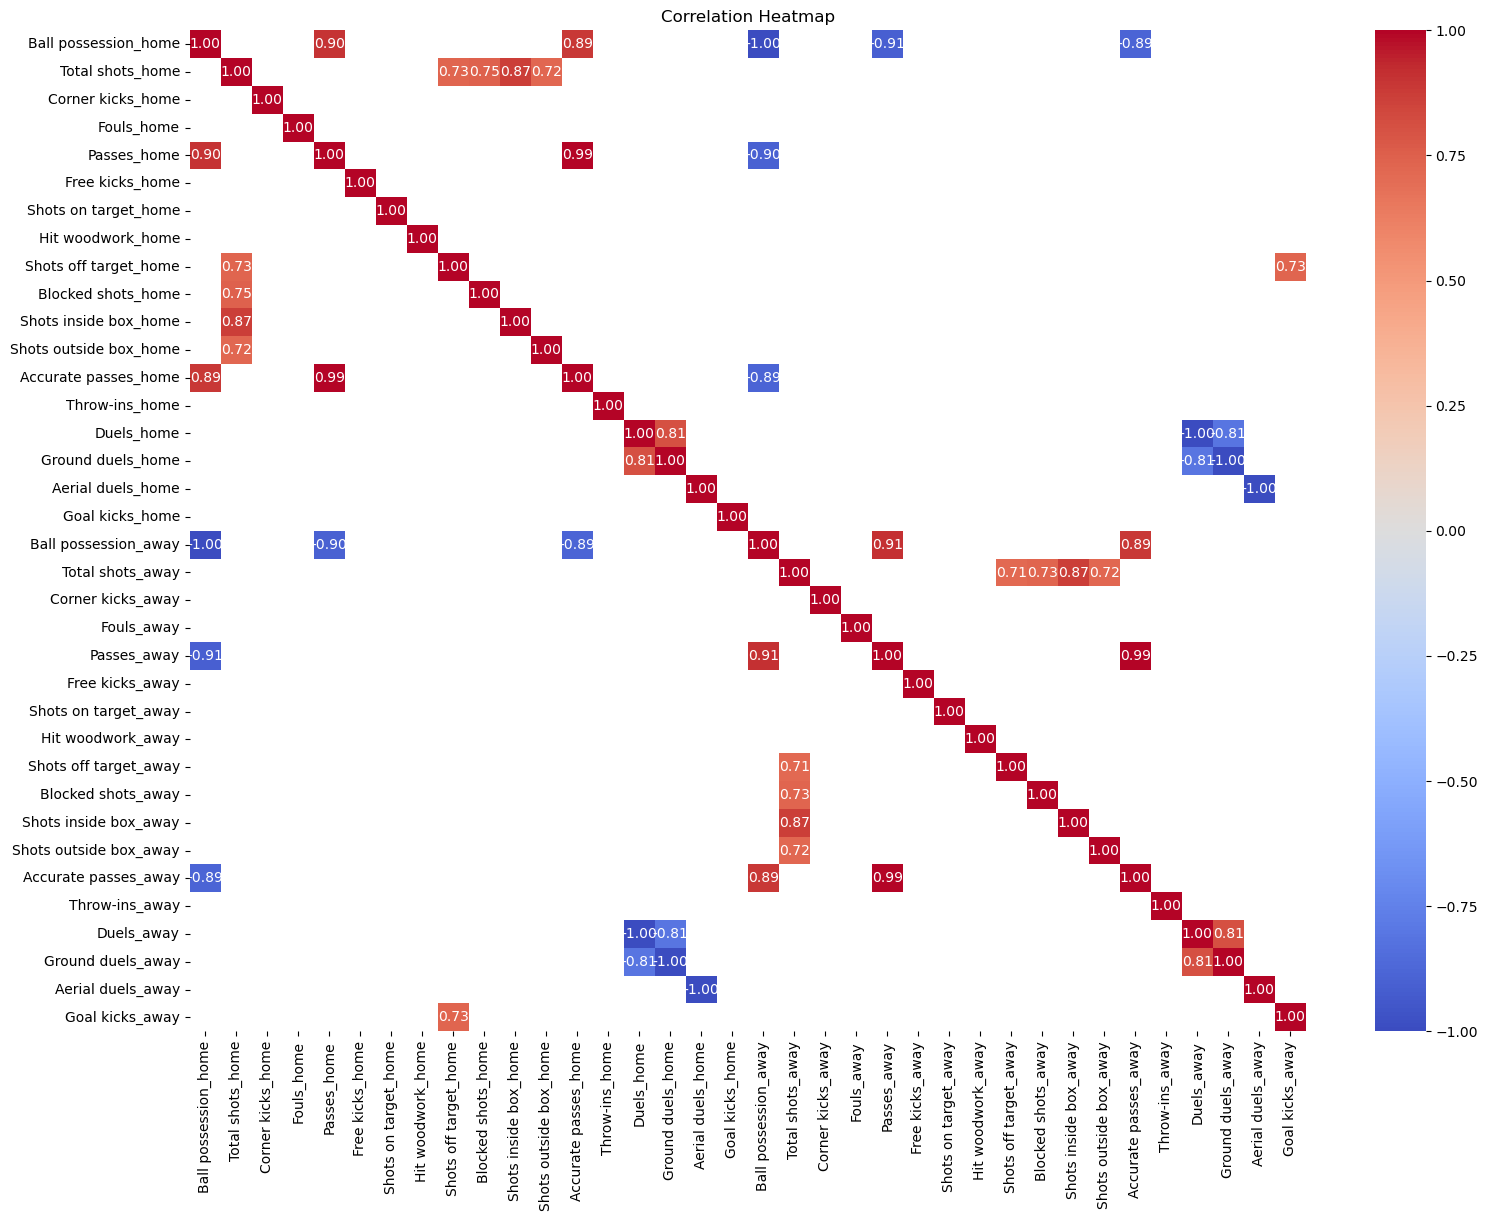

In [91]:
#correlation matrix, show only the correlation >0.7
def plot_correlation_matrix(df):
    """
    Plots a correlation matrix for the given DataFrame.
    """
    corr = df.corr()
    corr = corr[(abs(corr) > 0.7)]
    plt.figure(figsize=(18, 13))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', cbar=True)
    plt.title('Correlation Heatmap')
    plt.show()
plot_correlation_matrix(epl_stats.drop(columns=['id']))

In [92]:
def safe_divide(numerator, denominator):
    denominator=denominator.replace(0, 1)


    result = numerator / denominator
    result[(numerator == 0)] = 0
    
    return result


In [93]:
epl_stats['Blocked per shots on target_home'] = safe_divide(epl_stats['Blocked shots_home'], epl_stats['Shots on target_home'])
epl_stats['Blocked per shots on target_away'] = safe_divide(epl_stats['Blocked shots_away'], epl_stats['Shots on target_away'])

epl_stats['Shots on target per total shots_home'] = safe_divide(epl_stats['Shots on target_home'], epl_stats['Total shots_home'])
epl_stats['Shots on target per total shots_away'] = safe_divide(epl_stats['Shots on target_away'], epl_stats['Total shots_away'])

epl_stats['Hit woodwork per total shots_home'] = safe_divide(epl_stats['Hit woodwork_home'], epl_stats['Total shots_home'])
epl_stats['Hit woodwork per total shots_away'] = safe_divide(epl_stats['Hit woodwork_away'], epl_stats['Total shots_away'])

epl_stats['Shots inside box per total shots_home'] = safe_divide(epl_stats['Shots inside box_home'], epl_stats['Total shots_home'])
epl_stats['Shots inside box per total shots_away'] = safe_divide(epl_stats['Shots inside box_away'], epl_stats['Total shots_away'])

epl_stats['Shots outside box per total shots_home'] = safe_divide(epl_stats['Shots outside box_home'], epl_stats['Total shots_home'])
epl_stats['Shots outside box per total shots_away'] = safe_divide(epl_stats['Shots outside box_away'], epl_stats['Total shots_away'])

epl_stats["Pass accuracy_home"] = safe_divide(epl_stats['Accurate passes_home'], epl_stats['Passes_home'])
epl_stats["Pass accuracy_away"] = safe_divide(epl_stats['Accurate passes_away'], epl_stats['Passes_away'])

epl_stats['Game dominance_home'] = epl_stats['Ball possession_home']*epl_stats['Pass accuracy_home']
epl_stats['Game dominance_away'] = epl_stats['Ball possession_away']*epl_stats['Pass accuracy_away']
epl_stats['Overall game dominance'] = (epl_stats['Game dominance_home'] - epl_stats['Game dominance_away'])




#drop all the features that were engineered into new features
drop_features = ['Blocked shots_home', 'Blocked shots_away', 'Shots on target_home', 'Shots on target_away',
                 'Total shots_home', 'Total shots_away', 'Hit woodwork_home', 'Hit woodwork_away',
                 'Shots inside box_home', 'Shots inside box_away', 'Shots outside box_home', 'Shots outside box_away',
                 'Accurate passes_home', 'Accurate passes_away', 'Passes_home', 'Passes_away', 'Ball possession_home',
                 'Ball possession_away', 'Pass accuracy_home', 'Pass accuracy_away']
epl_stats.drop(columns=drop_features, inplace=True)
#drop all the columns that are not needed for the analysis
epl_stats=epl_stats.drop(columns=['Duels_home','Duels_away','Ground duels_away','Aerial duels_away',
                                  'Goal kicks_home','Goal kicks_away','Free kicks_home', 'Free kicks_away', 
                                  'Shots inside box per total shots_home','Shots inside box per total shots_away'])


In [94]:
epl_stats

,Corner kicks_home,Fouls_home,Shots off target_home,Throw-ins_home,Ground duels_home,Aerial duels_home,Corner kicks_away,Fouls_away,Shots off target_away,Throw-ins_away,...,Blocked per shots on target_away,Shots on target per total shots_home,Shots on target per total shots_away,Hit woodwork per total shots_home,Hit woodwork per total shots_away,Shots outside box per total shots_home,Shots outside box per total shots_away,Game dominance_home,Game dominance_away,Overall game dominance
0,7,0,6,20,0.56,0.51,3,0,6,15,...,1.000000,0.214286,0.250000,0.000000,0.000000,0.428571,0.500000,0.578537,0.210885,0.367651
1,4,0,4,23,0.44,0.47,7,0,3,21,...,1.666667,0.500000,0.272727,0.000000,0.000000,0.388889,0.727273,0.397542,0.451445,-0.053903
2,6,0,7,33,0.45,0.72,5,0,7,17,...,1.333333,0.285714,0.214286,0.047619,0.000000,0.571429,0.285714,0.590034,0.186290,0.403743
3,8,0,5,19,0.56,0.52,2,0,1,20,...,0.000000,0.500000,0.833333,0.071429,0.000000,0.357143,0.333333,0.308333,0.506250,-0.197917
4,7,0,5,25,0.60,0.48,8,0,5,22,...,1.200000,0.384615,0.312500,0.000000,0.000000,0.230769,0.375000,0.363415,0.424779,-0.061364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,3,13,3,19,0.56,0.33,0,11,2,12,...,4.000000,0.285714,0.142857,0.000000,0.000000,0.285714,0.428571,0.527032,0.354130,0.172902
3416,7,8,4,15,0.52,0.56,6,12,3,15,...,2.000000,0.538462,0.222222,0.076923,0.000000,0.307692,0.333333,0.537456,0.325762,0.211694
3417,3,12,3,15,0.40,0.35,9,9,9,16,...,1.000000,0.500000,0.235294,0.083333,0.000000,0.416667,0.352941,0.165991,0.668715,-0.502724
3418,1,14,5,17,0.51,0.52,8,10,7,10,...,1.333333,0.142857,0.214286,0.000000,0.071429,0.285714,0.214286,0.406308,0.457382,-0.051074


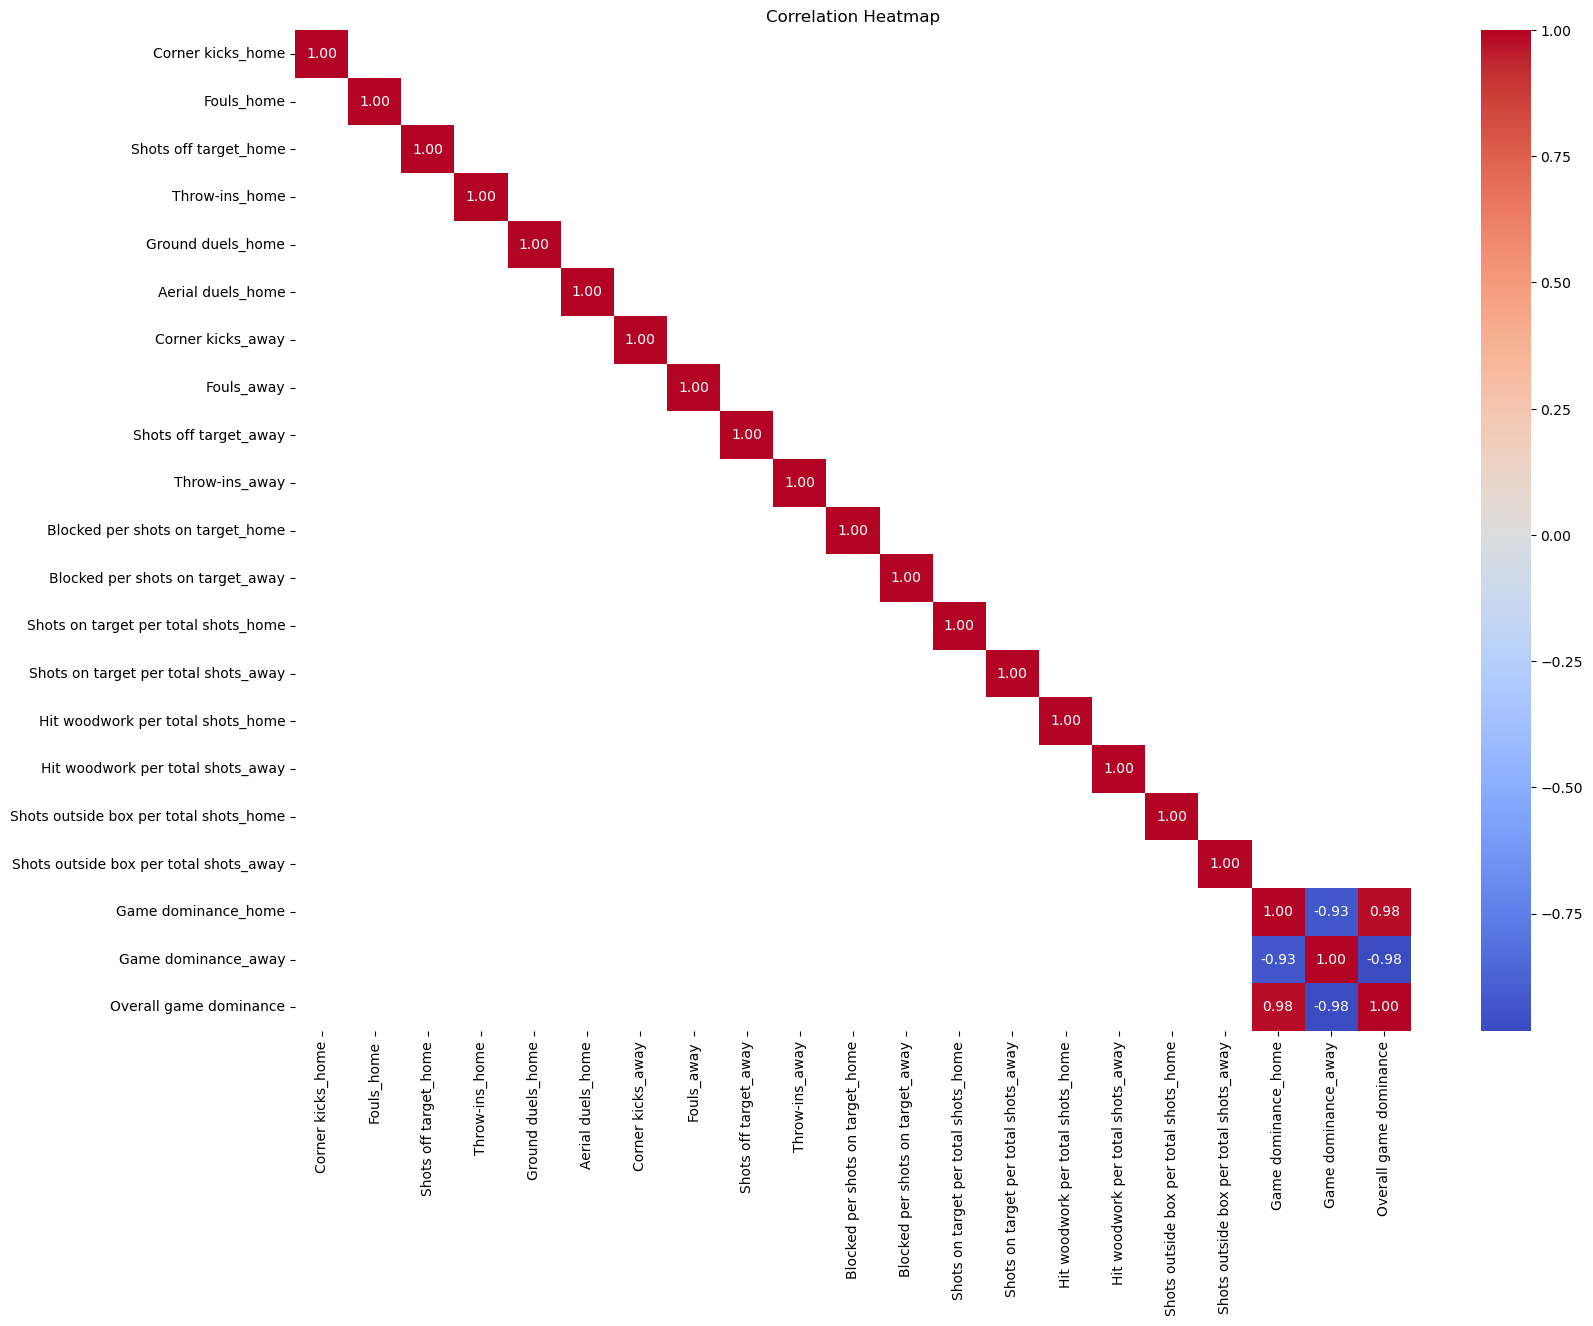

In [95]:
plot_correlation_matrix(epl_stats.drop(columns=['id']))

In [96]:
epl_stats.describe()

,Corner kicks_home,Fouls_home,Shots off target_home,Throw-ins_home,Ground duels_home,Aerial duels_home,Corner kicks_away,Fouls_away,Shots off target_away,Throw-ins_away,...,Blocked per shots on target_away,Shots on target per total shots_home,Shots on target per total shots_away,Hit woodwork per total shots_home,Hit woodwork per total shots_away,Shots outside box per total shots_home,Shots outside box per total shots_away,Game dominance_home,Game dominance_away,Overall game dominance
count,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,...,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000,3420.000000
mean,5.746784,9.494737,5.312281,21.235088,0.503982,0.504854,4.691813,9.739474,4.317251,20.387719,...,1.018693,0.345669,0.354024,0.025887,0.025151,0.366275,0.374114,0.410090,0.388113,0.021977
std,3.103306,4.536128,2.707463,6.293796,0.061928,0.102909,2.747818,4.705758,2.394714,6.285493,...,1.020974,0.151854,0.167845,0.046580,0.050519,0.155464,0.171365,0.131856,0.129597,0.256957
min,0.000000,0.000000,0.000000,5.000000,0.290000,0.100000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.089441,0.082976,-0.650284
25%,3.000000,7.000000,3.000000,17.000000,0.460000,0.440000,3.000000,7.000000,3.000000,16.000000,...,0.375000,0.250000,0.250000,0.000000,0.000000,0.263158,0.263158,0.309443,0.287054,-0.167895
50%,5.000000,10.000000,5.000000,21.000000,0.510000,0.500000,4.000000,10.000000,4.000000,20.000000,...,0.750000,0.333333,0.333333,0.000000,0.000000,0.361818,0.368421,0.404750,0.382990,0.022399
75%,8.000000,12.000000,7.000000,25.000000,0.550000,0.570000,6.000000,13.000000,6.000000,24.000000,...,1.333333,0.437500,0.454545,0.050000,0.000000,0.461538,0.500000,0.508201,0.480613,0.220377
max,19.000000,24.000000,18.000000,44.000000,0.730000,0.920000,19.000000,26.000000,14.000000,47.000000,...,9.000000,1.000000,1.000000,0.500000,0.400000,1.000000,1.000000,0.770305,0.772130,0.670993


FUNCTION fill_missing_with_regression(features, target_column):
    IF target_column has no missing values:
        RETURN target_column unchanged

    Split data into:
        - Training set (rows without NaNs)
        - Prediction set (rows with NaNs)

    Split training set further into:
        - Fit set
        - Validation set

    Initialize best_score = infinity
    Initialize best_model = None

    FOR degree in [1, 2, 3]:
        Train polynomial regression model of given degree
        Predict on validation set
        Compute Mean Absolute Error (MAE)

        IF MAE < best_score:
            Save model as best_model
            Save MAE and degree

    Use best_model to predict missing values
    Fill NaNs in target_column with predictions
    RETURN updated target_column


FOR each feature in dataset:
    IF feature contains NaNs:
        Fill missing values using fill_missing_with_regression()
    ELSE:
        Leave feature unchanged

Drop features where regression MAE is unacceptably high


In [97]:

def fill_na_with_best_regression(x, target_y):
    """
    Fills NaN values in target_y using the best-fit regression model (Linear, Poly(2), Poly(3)) based on MAE.
    
    Parameters:
        x (DataFrame or Series): Feature(s) to train on
        target_y (Series): Target variable with NaNs
    
    Returns:
        Series: target_y with NaNs filled
    """
    mask = target_y.isna()
    if mask.sum() == 0:
        print("No NaN values to fill.")
        return target_y

    # Split data into training and prediction sets
    x_train = x[~mask]
    y_train = target_y[~mask]
    x_pred = x[mask]

    # Handle single-feature case
    if isinstance(x_train, pd.Series):
        x_train = x_train.to_frame()
        x_pred = x_pred.to_frame()

    # Split for validation
    x_fit, x_val, y_fit, y_val = train_test_split(x_train, y_train, test_size=0.25, random_state=42)

    best_score = np.inf  # We want to minimize MAE
    best_model = None
    best_degree = None

    for degree in [1, 2, 3]:
        model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
        model.fit(x_fit, y_fit)
        y_val_pred = model.predict(x_val)

        mae = mean_absolute_error(y_val, y_val_pred)
        print(f"Degree {degree} MAE: {mae:.4f}")

        if mae < best_score:
            best_score = mae
            best_model = model
            best_degree = degree

    # Predict missing values using best model
    y_pred = np.round(best_model.predict(x_pred)).astype(int)
    target_y_filled = target_y.copy()
    target_y_filled[mask] = y_pred

    print(f"Selected degree with best MAE: {best_degree} ({best_score:.4f})")
    return target_y_filled

In [99]:
for i in drop_for_now:
    if dropped_df[i].isna().sum() > 0:
        print(f"Filling NaN values in column '{i}' using regression.")
        # Fill NaN values using the best-fit regression model
        dropped_df[i] = fill_na_with_best_regression(epl_stats.drop(columns=["id", 'Game dominance_home',
                 'Game dominance_away']), dropped_df[i])
    else:
        print(f"No NaN values in column '{i}'.")

Filling NaN values in column 'Big chances_home' using regression.
Degree 1 MAE: 1.1159
Degree 2 MAE: 1.0754
Degree 3 MAE: 2.5641
Selected degree with best MAE: 2 (1.0754)
Filling NaN values in column 'Big chances_away' using regression.
Degree 1 MAE: 0.9964
Degree 2 MAE: 1.0179
Degree 3 MAE: 2.6889
Selected degree with best MAE: 1 (0.9964)
Filling NaN values in column 'Fouled in final third_away' using regression.
Degree 1 MAE: 1.0933
Degree 2 MAE: 1.1438
Degree 3 MAE: 2.7413
Selected degree with best MAE: 1 (1.0933)
Filling NaN values in column 'Fouled in final third_home' using regression.
Degree 1 MAE: 1.1008
Degree 2 MAE: 1.1478
Degree 3 MAE: 2.7054
Selected degree with best MAE: 1 (1.1008)
Filling NaN values in column 'Long balls_away' using regression.
Degree 1 MAE: 0.0670
Degree 2 MAE: 0.0698
Degree 3 MAE: 0.1682
Selected degree with best MAE: 1 (0.0670)
Filling NaN values in column 'Clearances_home' using regression.
Degree 1 MAE: 5.4227
Degree 2 MAE: 5.5897
Degree 3 MAE: 14.13

In [100]:
high_mae_features = [
    'Clearances_home',
    'Tackles_away',
    'Final third entries_away',
    'Total tackles_home',
    'Dispossessed_away',
    'Total tackles_away',
    'Interceptions_away',
    'Interceptions_home',
    'Clearances_away',
    'Final third entries_home',
    'Tackles_home',
    'Dispossessed_home'
]

dropped_df.drop(columns=high_mae_features, inplace=True)

In [101]:
dropped_df

,Big chances_home,Big chances_away,Fouled in final third_away,Fouled in final third_home,Long balls_away,Tackles won_home,Crosses_away,Dribbles_away,Tackles won_away,Dribbles_home,...,Long balls_home,Yellow cards_home,Yellow cards_away,Offsides_away,Offsides_home,Total saves_away,Goalkeeper saves_away,Total saves_home,Goalkeeper saves_home,id
0,2.0,2.0,0.0,0.0,0.00,1.00,0.00,0.00,1.00,1.00,...,1.00,1.0,0.0,2.0,3.0,2.0,2.0,3.0,3.0,6768365
1,3.0,1.0,1.0,0.0,0.00,1.00,0.00,1.00,1.00,0.00,...,0.00,2.0,4.0,0.0,1.0,6.0,6.0,2.0,2.0,6768337
2,2.0,2.0,0.0,1.0,0.00,1.00,0.00,1.00,1.00,1.00,...,1.00,3.0,2.0,0.0,1.0,5.0,5.0,2.0,2.0,6768390
3,3.0,3.0,0.0,1.0,1.00,1.00,0.00,0.00,1.00,1.00,...,0.00,2.0,1.0,0.0,3.0,3.0,3.0,3.0,3.0,6768392
4,2.0,2.0,0.0,0.0,0.00,1.00,0.00,0.00,1.00,1.00,...,0.00,3.0,9.0,0.0,3.0,3.0,3.0,3.0,3.0,6768354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3415,2.0,0.0,0.0,3.0,0.58,0.64,0.60,0.56,0.40,0.74,...,0.60,1.0,5.0,4.0,1.0,3.0,3.0,1.0,1.0,11352389
3416,5.0,0.0,2.0,1.0,0.45,0.56,0.17,0.82,0.71,0.57,...,0.54,3.0,4.0,1.0,1.0,3.0,3.0,2.0,2.0,11352337
3417,2.0,1.0,6.0,1.0,0.41,0.43,0.29,0.71,0.69,0.63,...,0.32,4.0,3.0,2.0,3.0,3.0,3.0,3.0,3.0,11352418
3418,1.0,3.0,3.0,2.0,0.44,0.71,0.19,0.50,0.50,0.53,...,0.53,2.0,3.0,2.0,0.0,2.0,2.0,2.0,2.0,11352346


In [102]:
#merge epl_stats and dropped_df on 'id'
epl_stats = pd.merge(epl_stats, dropped_df, on='id', how='left')

In [103]:

#drop all the columns that are used to engineer the new features and the unneccessary columns
drop_features = [ 'Total saves_home', 'Total saves_away']

In [104]:
epl_stats.drop(columns=drop_features, inplace=True)

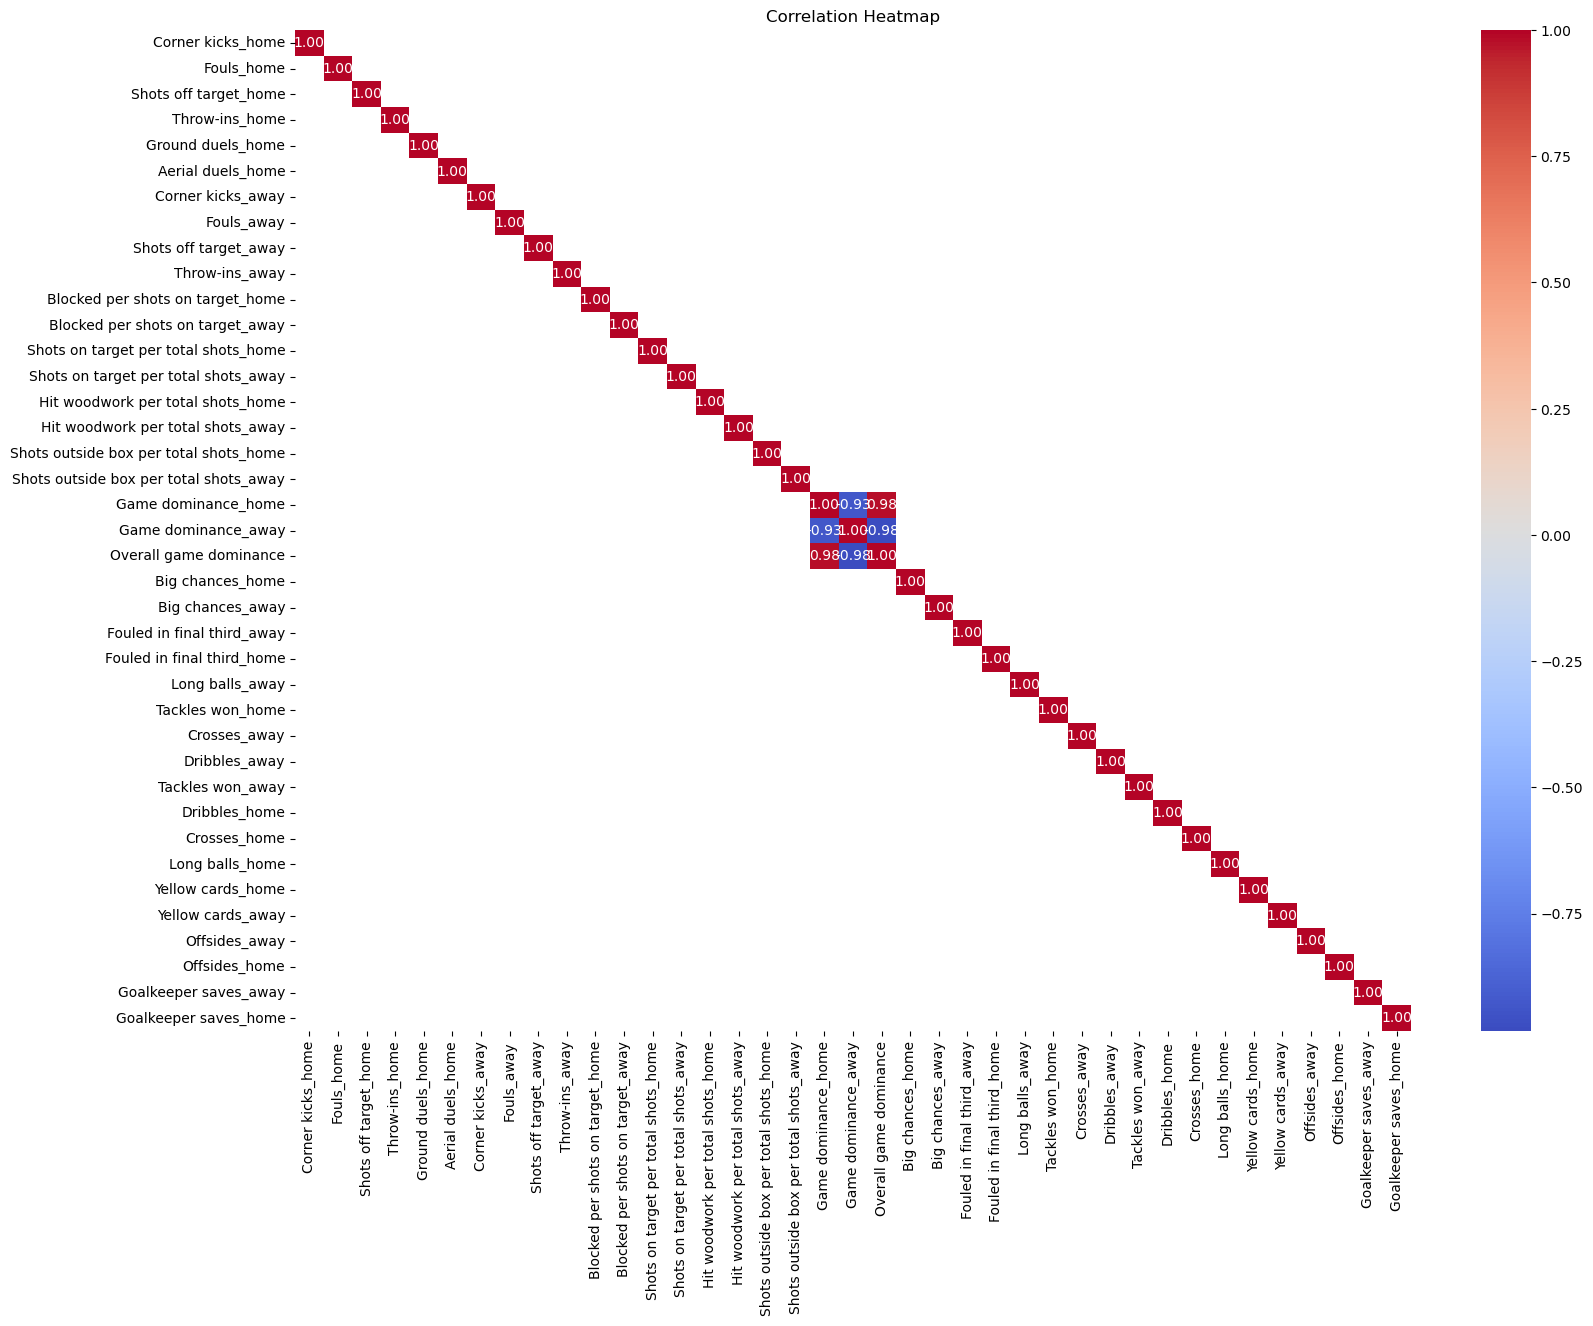

In [105]:
plot_correlation_matrix(epl_stats.drop(columns=['id']))

In [108]:
epl_stats.columns

Index(['Corner kicks_home', 'Fouls_home', 'Shots off target_home',
       'Throw-ins_home', 'Ground duels_home', 'Aerial duels_home',
       'Corner kicks_away', 'Fouls_away', 'Shots off target_away',
       'Throw-ins_away', 'id', 'Blocked per shots on target_home',
       'Blocked per shots on target_away',
       'Shots on target per total shots_home',
       'Shots on target per total shots_away',
       'Hit woodwork per total shots_home',
       'Hit woodwork per total shots_away',
       'Shots outside box per total shots_home',
       'Shots outside box per total shots_away', 'Game dominance_home',
       'Game dominance_away', 'Overall game dominance', 'Big chances_home',
       'Big chances_away', 'Fouled in final third_away',
       'Fouled in final third_home', 'Long balls_away', 'Tackles won_home',
       'Crosses_away', 'Dribbles_away', 'Tackles won_away', 'Dribbles_home',
       'Crosses_home', 'Long balls_home', 'Yellow cards_home',
       'Yellow cards_away', 'Offsides

In [110]:
epl_stats.to_csv("Data/stats_epl1524_processed.csv", index=False)

In [2]:
epl_stats= pd.read_csv("Data/stats_epl1524_processed.csv")

NameError: name 'pd' is not defined